# Tasks for laboratory assignment 3

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

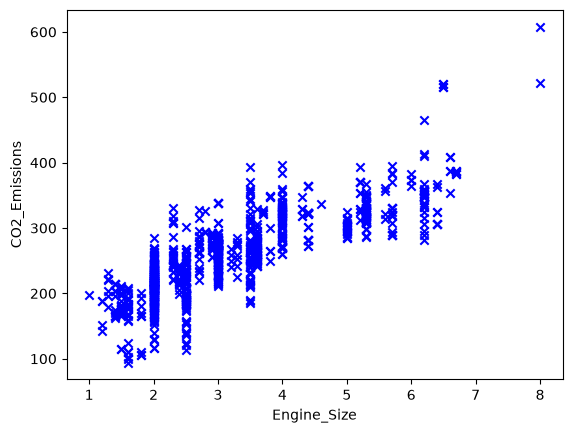

In [86]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [87]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    data = pd.read_csv(file_path)
    return data.astype(str).agg(" ".join, axis=1).tolist()

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

['63 1 3 145 233 1 0 150 0 2.3 0 0 1 1', '37 1 2 130 250 0 1 187 0 3.5 0 0 2 1', '41 0 1 130 204 0 0 172 0 1.4 2 0 2 1', '56 1 1 120 236 0 1 178 0 0.8 2 0 2 1', '57 0 0 120 354 0 1 163 1 0.6 2 0 2 1', '57 1 0 140 192 0 1 148 0 0.4 1 0 1 1', '56 0 1 140 294 0 0 153 0 1.3 1 0 2 1', '44 1 1 120 263 0 1 173 0 0.0 2 0 3 1', '52 1 2 172 199 1 1 162 0 0.5 2 0 3 1', '57 1 2 150 168 0 1 174 0 1.6 2 0 2 1', '54 1 0 140 239 0 1 160 0 1.2 2 0 2 1', '48 0 2 130 275 0 1 139 0 0.2 2 0 2 1', '49 1 1 130 266 0 1 171 0 0.6 2 0 2 1', '64 1 3 110 211 0 0 144 1 1.8 1 0 2 1', '58 0 3 150 283 1 0 162 0 1.0 2 0 2 1', '50 0 2 120 219 0 1 158 0 1.6 1 0 2 1', '58 0 2 120 340 0 1 172 0 0.0 2 0 2 1', '66 0 3 150 226 0 1 114 0 2.6 0 0 2 1', '43 1 0 150 247 0 1 171 0 1.5 2 0 2 1', '69 0 3 140 239 0 1 151 0 1.8 2 2 2 1', '59 1 0 135 234 0 1 161 0 0.5 1 0 3 1', '44 1 2 130 233 0 1 179 1 0.4 2 0 2 1', '42 1 0 140 226 0 1 178 0 0.0 2 0 2 1', '61 1 2 150 243 1 1 137 1 1.0 1 0 2 1', '40 1 3 140 199 0 1 178 1 1.4 2 0 3 1',

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

In [88]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import numpy as np

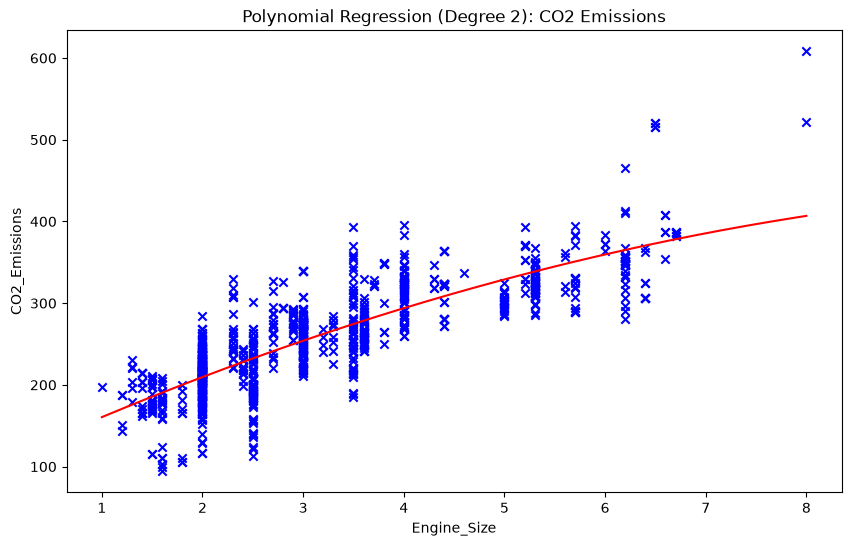

[np.float64(106.80347772377965),
 np.float64(56.025801806461075),
 np.float64(-2.315381879015182)]

In [89]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data[["Engine_Size"]]
    y = data["CO2_Emissions"]

    poly = PolynomialFeatures(degree=2, include_bias=False)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    X_plot = np.linspace(X["Engine_Size"].min(),
                         X["Engine_Size"].max(), 200).reshape(-1, 1)
    X_plot_poly = poly.transform(
    pd.DataFrame(X_plot, columns=["Engine_Size"])
)
    y_plot = model.predict(X_plot_poly)

    plt.figure(figsize=(10, 6))
    plt.scatter(X["Engine_Size"], y, color="blue", marker="x")
    plt.plot(X_plot, y_plot, color="red")

    plt.xlabel("Engine_Size")
    plt.ylabel("CO2_Emissions")
    plt.title("Polynomial Regression (Degree 2): CO2 Emissions")
    plt.show()

    return [model.intercept_, *model.coef_]


data = pd.read_csv("resources/CO2_emission.csv")
CO2_emissions(data)

In [90]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [91]:
X = data[["Engine_Size"]]
y = data["CO2_Emissions"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

poly_pred = poly_model.predict(X_test_poly)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (degree 2)"],
    "R2": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, poly_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, poly_pred))
    ]
})

print(results)


                              Model        R2       RMSE
0                 Linear Regression  0.642036  37.973116
1  Polynomial Regression (degree 2)  0.653629  37.353169


## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

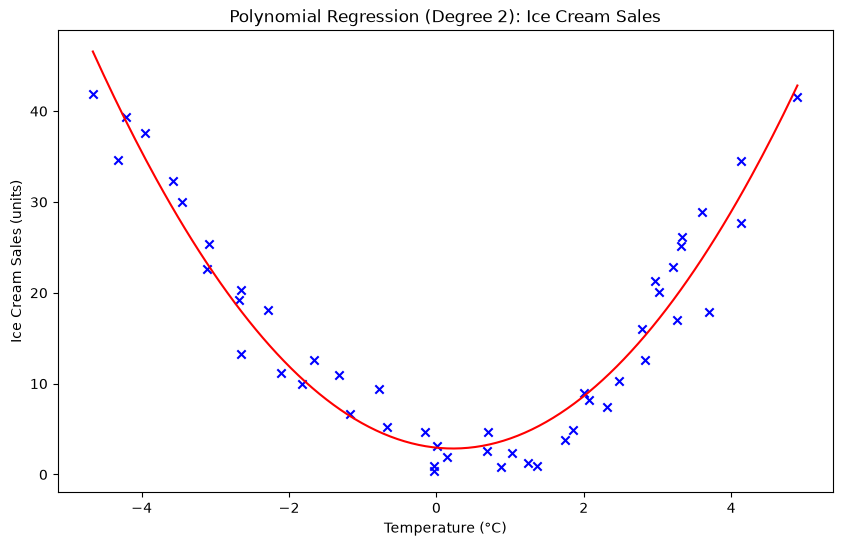

Theta parameters: [np.float64(2.951774157993448), np.float64(-0.8246816702106482), np.float64(1.829526229670208)]


In [93]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data[["Temperature (°C)"]]
    y = data["Ice Cream Sales (units)"]

    poly = PolynomialFeatures(degree=2, include_bias=False)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    X_plot = np.linspace(
        X["Temperature (°C)"].min(),
        X["Temperature (°C)"].max(),
        200
    ).reshape(-1, 1)

    X_plot = pd.DataFrame(X_plot, columns=["Temperature (°C)"])
    y_plot = model.predict(poly.transform(X_plot))

    plt.figure(figsize=(10, 6))
    plt.scatter(X["Temperature (°C)"], y, color="blue", marker="x")
    plt.plot(X_plot["Temperature (°C)"], y_plot, color="red")

    plt.xlabel("Temperature (°C)")
    plt.ylabel("Ice Cream Sales (units)")
    plt.title("Polynomial Regression (Degree 2): Ice Cream Sales")
    plt.show()

    return [model.intercept_, *model.coef_]

data = pd.read_csv('resources/ice_cream_selling_data.csv')
theta = ice_cream_selling(data)
print("Theta parameters:", theta)

In [94]:
data = pd.read_csv("resources/ice_cream_selling_data.csv")

X = data[["Temperature (°C)"]]
y = data["Ice Cream Sales (units)"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

results = []

for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    results.append({
        "Model": "Linear Regression" if degree == 1
                 else f"Polynomial Regression (degree {degree})",
        "R2": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    })

results_df = pd.DataFrame(results)
print(results_df)


                              Model        R2       RMSE
0                 Linear Regression -0.575127  12.219914
1  Polynomial Regression (degree 2)  0.843055   3.857304
2  Polynomial Regression (degree 3)  0.840511   3.888446


## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [96]:
data = pd.read_csv("resources/powerconsumption.csv")

print("Columns:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
print(data.head())

print("\nMissing values:")
print(data.isnull().sum().to_string())

print("\nDataset shape:")
print(data.shape)


Columns:
['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

First 5 rows:
        Datetime  Temperature  Humidity  WindSpeed  GeneralDiffuseFlows  \
0  1/1/2017 0:00        6.559      73.8      0.083                0.051   
1  1/1/2017 0:10        6.414      74.5      0.083                0.070   
2  1/1/2017 0:20        6.313      74.5      0.080                0.062   
3  1/1/2017 0:30        6.121      75.0      0.083                0.091   
4  1/1/2017 0:40        5.921      75.7      0.081                0.048   

   DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  \
0         0.119             34055.69620             16128.87538   
1         0.085             29814.68354             19375.07599   
2         0.100             29128.10127             19006.68693   
3         0.096             28228.86076             18361.09422   
4         0.085     

In [97]:
data = pd.read_csv("resources/powerconsumption.csv")

data["TotalPowerConsumption"] = (
    data["PowerConsumption_Zone1"]
    + data["PowerConsumption_Zone2"]
    + data["PowerConsumption_Zone3"]
)

X = data[["Temperature", "Humidity", "WindSpeed"]]
y = data["TotalPowerConsumption"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

results = []

for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    results.append({
        "Model": "Linear Regression" if degree == 1
                 else f"Polynomial Regression (degree {degree})",
        "R2": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    })

results_df = pd.DataFrame(results)
print(results_df)


                              Model        R2          RMSE
0                 Linear Regression  0.250681  14783.622249
1  Polynomial Regression (degree 2)  0.291109  14379.280489
2  Polynomial Regression (degree 3)  0.303760  14250.396214


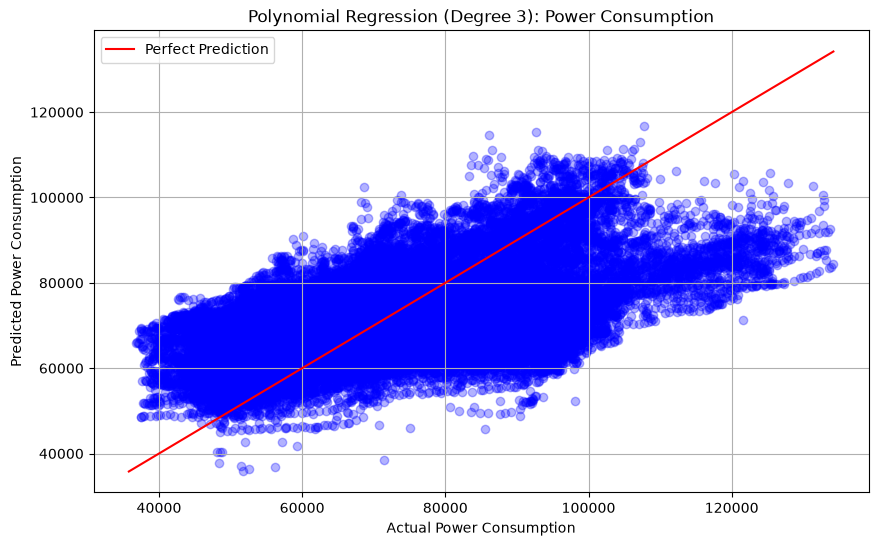

Theta parameters: [np.float64(176649.87668581033), np.float64(1217.4945280270313), np.float64(-4953.925935627331), np.float64(7.203468038051918), np.float64(-246.0097981759389), np.float64(50.96171084577121), np.float64(-293.1572104528429), np.float64(67.68532814599153), np.float64(-85.47035693393617), np.float64(93.258814240203), np.float64(4.220408820322203), np.float64(1.2554500828883037), np.float64(4.623880399671087), np.float64(-0.4204128406343433), np.float64(-2.424641039791465), np.float64(72.14078318125473), np.float64(-0.3263002343893294), np.float64(-0.7387503654732532), np.float64(41.25505213741418), np.float64(-222.35371115620248)]


In [98]:
def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. 
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data[["Temperature", "Humidity", "WindSpeed"]]

    y = (
        data["PowerConsumption_Zone1"]
        + data["PowerConsumption_Zone2"]
        + data["PowerConsumption_Zone3"]
    )

    poly = PolynomialFeatures(degree=3, include_bias=False)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    y_pred = model.predict(X_poly)

    plt.figure(figsize=(10, 6))
    plt.scatter(y, y_pred, color="blue", alpha=0.3)

    min_value = min(y.min(), y_pred.min())
    max_value = max(y.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        color="red",
        label="Perfect Prediction"
    )

    plt.xlabel("Actual Power Consumption")
    plt.ylabel("Predicted Power Consumption")
    plt.title("Polynomial Regression (Degree 3): Power Consumption")
    plt.legend()
    plt.grid(True)
    plt.show()

    return [model.intercept_, *model.coef_]


data = pd.read_csv("resources/powerconsumption.csv")
theta = power_consumption(data)

print("Theta parameters:", theta)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier

In [100]:
data = pd.read_csv("resources/heart.csv")

print("Columns:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
print(data.head())

print("\nMissing values:")
print(data.isnull().sum().to_string())

print("\nDataset shape:")
print(data.shape)

print("\nTarget distribution:")
print(data["output"].value_counts())


Columns:
['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall', 'output']

First 5 rows:
   age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0   63    1   3     145   233    1        0       150     0      2.3    0   
1   37    1   2     130   250    0        1       187     0      3.5    0   
2   41    0   1     130   204    0        0       172     0      1.4    2   
3   56    1   1     120   236    0        1       178     0      0.8    2   
4   57    0   0     120   354    0        1       163     1      0.6    2   

   caa  thall  output  
0    0      1       1  
1    0      2       1  
2    0      2       1  
3    0      2       1  
4    0      2       1  

Missing values:
age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0

Dataset shape:
(303, 14)

Target d

In [101]:
X = data.drop(columns=["output"])
y = data["output"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Ridge Classifier": RidgeClassifier(),
    "SGD Classifier": SGDClassifier(random_state=42)
}

results = []

for name, model in models.items():
    pipeline = make_pipeline(StandardScaler(), model)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


              Model  Accuracy  Precision   Recall       F1
Logistic Regression  0.803279   0.769231 0.909091 0.833333
   Ridge Classifier  0.786885   0.750000 0.909091 0.821918
     SGD Classifier  0.852459   0.815789 0.939394 0.873239


Accuracy: 0.8524590163934426
Precision: 0.8157894736842105
Recall: 0.9393939393939394
F1: 0.8732394366197183


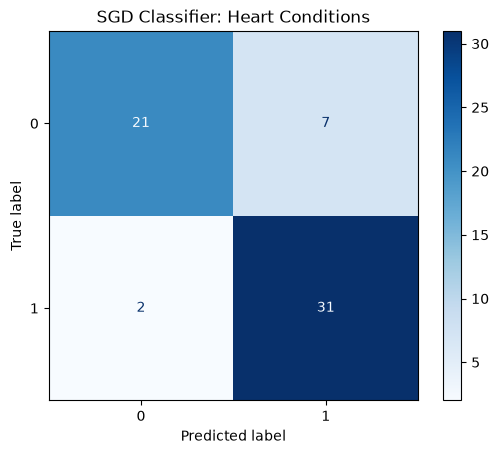

Theta parameters: [0.7451738994482808, 1.051069956031081, -5.889398328039363, 5.450409414270406, 0.9165451409150984, -1.464954086184652, -2.0688429710282646e-15, -1.411681086113404e-14, 5.127890802293857, -5.79550581457404, -3.646044137109978, -4.5879635298685633e-14, -9.225121724484726, -9.086772646160522]


In [102]:
def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack. 
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data.drop(columns=["output"])
    y = data["output"]

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = SGDClassifier(random_state=42)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)

    print("Accuracy:", accuracy_score(y_val, y_pred))
    print("Precision:", precision_score(y_val, y_pred))
    print("Recall:", recall_score(y_val, y_pred))
    print("F1:", f1_score(y_val, y_pred))

    ConfusionMatrixDisplay.from_predictions(
        y_val, y_pred, cmap="Blues"
    )
    plt.title("SGD Classifier: Heart Conditions")
    plt.show()

    return [float(model.intercept_[0]), *model.coef_[0].tolist()]

theta = heart_classification(data)

print("Theta parameters:", theta)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

In [103]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [104]:
import os

files = os.listdir("resources")

for file in files:
    print(file)


bitcoin.csv
cars_clus.csv
cell_samples.csv
china_gdp.csv
churn_Data.csv
CO2_emission.csv
cust_segmentation_Data.csv
data.csv
data.json
drug.csv
example.csv
heart.csv
ice_cream_selling_data.csv
movies.csv
o2Saturation.csv
powerconsumption.csv
ratings.csv
Salary_dataset.csv
sales.csv
telecom_cus.csv
weather.csv
weather.json


In [105]:
data = pd.read_csv("resources/cust_segmentation_Data.csv")

print("Columns:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
print(data.head())

print("\nMissing values:")
print(data.isnull().sum())

print("\nDataset shape:")
print(data.shape)


Columns:
['Customer Id', 'Age', 'Edu', 'Years Employed', 'Income', 'Card Debt', 'Other Debt', 'Defaulted', 'DebtIncomeRatio']

First 5 rows:
   Customer Id  Age  Edu  Years Employed  Income  Card Debt  Other Debt  \
0            1   41    2               6      19      0.124       1.073   
1            2   47    1              26     100      4.582       8.218   
2            3   33    2              10      57      6.111       5.802   
3            4   29    2               4      19      0.681       0.516   
4            5   47    1              31     253      9.308       8.908   

   Defaulted  DebtIncomeRatio  
0        0.0              6.3  
1        0.0             12.8  
2        1.0             20.9  
3        0.0              6.3  
4        0.0              7.2  

Missing values:
Customer Id          0
Age                  0
Edu                  0
Years Employed       0
Income               0
Card Debt            0
Other Debt           0
Defaulted          150
DebtIncomeRatio

Missing values:
Income             0
Card Debt          0
DebtIncomeRatio    0
dtype: int64


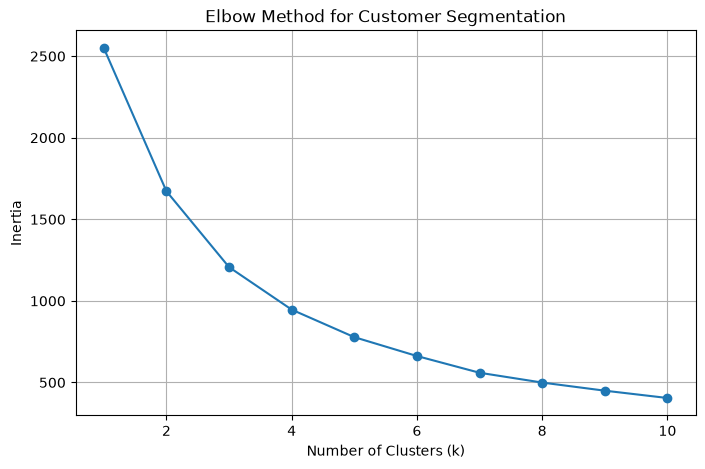

In [106]:
data = pd.read_csv("resources/cust_segmentation_Data.csv")

features = ["Income", "Card Debt", "DebtIncomeRatio"]
X = data[features].copy()

print("Missing values:")
print(X.isnull().sum())

X = X.dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.grid(True)
plt.show()


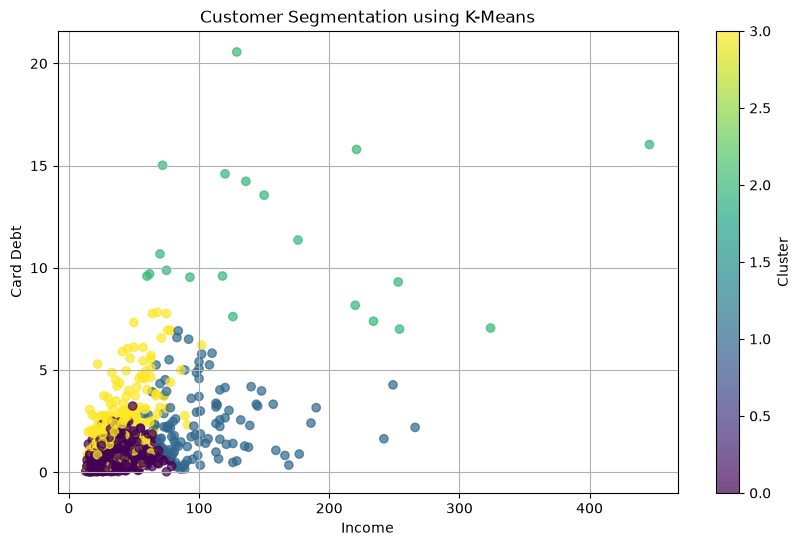

Customers per cluster:
Cluster
0    511
1    106
2     20
3    213
Name: count, dtype: int64
Predicted cluster for new customer: 3


[[-0.34510799810125725, -0.43155510884951853, -0.5091806903515473],
 [1.5013908924481119, 0.41052526788012267, -0.36566359732207165],
 [3.122365932800287, 4.592094915586903, 1.328027625627469],
 [-0.21241580387682138, 0.3998454643900136, 1.2788315566818356]]

In [107]:
def additional(data):
    features = ["Income", "Card Debt", "DebtIncomeRatio"]
    X = data[features].dropna().copy()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    model = KMeans(n_clusters=4, random_state=42, n_init=10)
    clusters = model.fit_predict(X_scaled)

    X["Cluster"] = clusters

    plt.figure(figsize=(10, 6))
    plt.scatter(
        X["Income"],
        X["Card Debt"],
        c=X["Cluster"],
        cmap="viridis",
        alpha=0.7
    )

    plt.xlabel("Income")
    plt.ylabel("Card Debt")
    plt.title("Customer Segmentation using K-Means")
    plt.colorbar(label="Cluster")
    plt.grid(True)
    plt.show()

    print("Customers per cluster:")
    print(X["Cluster"].value_counts().sort_index())

    new_customer = pd.DataFrame({
        "Income": [50],
        "Card Debt": [3.5],
        "DebtIncomeRatio": [12.0]
    })

    new_customer_scaled = scaler.transform(new_customer)
    predicted_cluster = model.predict(new_customer_scaled)

    print("Predicted cluster for new customer:", predicted_cluster[0])

    return model.cluster_centers_.tolist()


data = pd.read_csv("resources/cust_segmentation_Data.csv")
additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



In [108]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [109]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

# If loading dataset via kaggle package fails (some of these do right now when I try because of encoding issues), 
# donwload the dataset manually from webpage and place csv file(s) in the resources folder.
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    # Placeholder for classification logic
    print("Classifying text data...")
    # You can implement your text classification logic here

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (107018, 3)

Columns:
['Id', 'Review', 'Label']

First 5 rows:
   Id                                             Review  Label
0   0                               good and interesting      5
1   1  This class is very helpful to me. Currently, I...      5
2   2  like!Prof and TAs are helpful and the discussi...      5
3   3  Easy to follow and includes a lot basic and im...      5
4   4  Really nice teacher!I could got the point eazl...      4

Missing values:
Id        0
Review    0
Label     0
dtype: int64


In [110]:
X = df["Review"]
y = df["Label"]

print("Rating distribution:")
print(y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(max_iter=3000)
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000)),
        ("model", classifier)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro")
    })

results_df = pd.DataFrame(results)
print("\nModel comparison:")
print(results_df)


Rating distribution:
Label
1     2469
2     2251
3     5071
4    18054
5    79173
Name: count, dtype: int64

Model comparison:
                 Model  Accuracy  F1 (weighted)  F1 (macro)
0  Logistic Regression  0.782938       0.748727    0.426095
1           Linear SVM  0.775930       0.739466    0.407689


Classification Report:
              precision    recall  f1-score   support

           1       0.58      0.39      0.47       494
           2       0.32      0.11      0.16       450
           3       0.36      0.19      0.25      1014
           4       0.49      0.28      0.35      3611
           5       0.83      0.97      0.90     15835

    accuracy                           0.78     21404
   macro avg       0.52      0.39      0.43     21404
weighted avg       0.74      0.78      0.75     21404



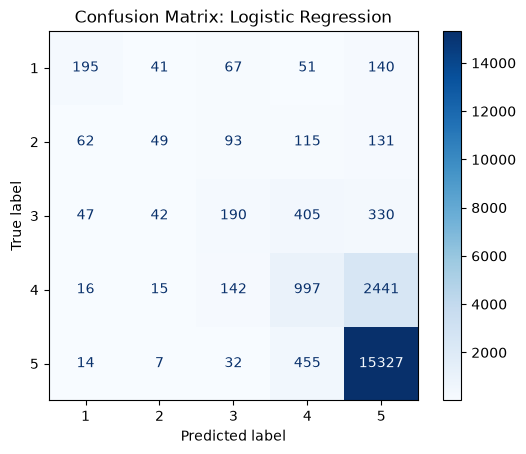

In [111]:
best_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10000)),
    ("model", LogisticRegression(max_iter=1000))
])

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix: Logistic Regression")
plt.show()